# Baseline: OLS on LLM traits + YouTube metadata

In [1]:
"""Baseline model: plain linear regression (no regularization, no scaling, no feature selection) of each video's
engagement on its LLM-scored traits, YouTube API metadata and tag dummies. Trait scores on the 0-4 (Linear) scale are
one-hot encoded; the Binary traits stay 0/1. Uses only videos tagged before config.ANALYSIS_TAGGED_BEFORE.
Evaluation: a random 20% test set is held out; 5-fold CV runs on the remaining 80%."""
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression  # only for the rank check below
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import OneHotEncoder

sys.path.insert(0, os.path.abspath("../src"))
import config
from traits import get_traits

## Load: tagged traits + metadata + engagement

In [2]:
traits = get_traits()
linear_cols = [trait["column"] for trait in traits if trait["scale"] == "linear"]
binary_cols = [trait["column"] for trait in traits if trait["scale"] == "binary"]
trait_sql = ", ".join(f"t.{col}" for col in linear_cols + binary_cols)
dataset = f"{config.GCP_PROJECT_ID}.{config.BQ_DATASET}"

client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)
df_raw = client.query(f"""
    SELECT t.id, t.channel_id, {trait_sql},
        v.statistics_viewCount AS views, v.statistics_likeCount AS likes,
        v.duration_seconds, v.age_days_at_pull, v.snippet_publishedAt, v.snippet_title, v.snippet_description,
        v.snippet_tags, v.contentDetails_definition, v.contentDetails_caption,
        v.paidProductPlacementDetails_hasPaidProductPlacement AS has_paid_placement,
        CAST(c.statistics_subscriberCount AS INT64) AS channel_subscribers
    FROM `{dataset}.llm_tagged` AS t
    JOIN `{dataset}.videos` AS v ON t.id = v.id
    JOIN `{dataset}.channels` AS c ON v.snippet_channelId = c.id
    WHERE t.tagged_at < TIMESTAMP("{config.ANALYSIS_TAGGED_BEFORE}")
    ORDER BY t.id  -- BigQuery row order is not stable; the 80/20 split is positional, so fix the order
""").to_dataframe()
print(f"tagged before {config.ANALYSIS_TAGGED_BEFORE}: {len(df_raw)} videos from {df_raw['channel_id'].nunique()} channels; {len(linear_cols)} linear + {len(binary_cols)} binary traits")

# YouTube tag vocabulary: lowercase tags used in at least MIN_TAG_VIDEOS videos across at least MIN_TAG_CHANNELS channels,
# counted over the whole dataset (not just the tagged sample). The channel rule drops tags that only identify one channel.
MIN_TAG_VIDEOS = 50
MIN_TAG_CHANNELS = 3
df_tag_vocab = client.query(f"""
    SELECT tag, COUNT(DISTINCT v.id) AS n_videos, COUNT(DISTINCT v.snippet_channelId) AS n_channels
    FROM `{dataset}.videos` AS v, UNNEST(SPLIT(LOWER(v.snippet_tags), '|')) AS raw_tag
    CROSS JOIN UNNEST([TRIM(raw_tag)]) AS tag
    WHERE v.snippet_tags IS NOT NULL AND tag != ''
    GROUP BY tag
    HAVING n_videos >= {MIN_TAG_VIDEOS} AND n_channels >= {MIN_TAG_CHANNELS}
""").to_dataframe()
print(f"{len(df_tag_vocab)} tags in the vocabulary (>= {MIN_TAG_VIDEOS} videos and >= {MIN_TAG_CHANNELS} channels)")

/private/tmp/claude-501/-Users-leoyang-Downloads-Github-Repos-DSO-585-project/c234077b-c684-4e3e-a33f-865c0d53ac7a/scratchpad/venv/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


tagged before 2026-10-15 22:30:00 UTC: 726 videos from 48 channels; 75 linear + 4 binary traits


/private/tmp/claude-501/-Users-leoyang-Downloads-Github-Repos-DSO-585-project/c234077b-c684-4e3e-a33f-865c0d53ac7a/scratchpad/venv/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


57 tags in the vocabulary (>= 50 videos and >= 3 channels)


## Features and targets

In [3]:
# Metadata features: everything knowable about a video from the YouTube API except its own engagement counts.
df_model = df_raw.dropna(subset=linear_cols + binary_cols + ["views", "likes"]).copy()
df_model["publish_hour"] = df_model["snippet_publishedAt"].dt.hour
df_model["publish_weekday"] = df_model["snippet_publishedAt"].dt.dayofweek
df_model["title_length"] = df_model["snippet_title"].str.len()
df_model["description_length"] = df_model["snippet_description"].fillna("").str.len()
df_model["n_tags"] = df_model["snippet_tags"].fillna("").apply(lambda tags: len(tags.split("|")) if tags else 0)
df_model["is_hd"] = (df_model["contentDetails_definition"] == "hd").astype(int)
df_model["has_caption"] = (df_model["contentDetails_caption"] == "true").astype(int)
df_model["has_paid_placement"] = df_model["has_paid_placement"].fillna(False).astype(int)
df_model[linear_cols + binary_cols] = df_model[linear_cols + binary_cols].astype(int)

metadata_cols = ["duration_seconds", "age_days_at_pull", "channel_subscribers", "publish_hour", "publish_weekday",
                 "title_length", "description_length", "n_tags", "is_hd", "has_caption", "has_paid_placement"]

# Tag dummies: 1 if the video carries the tag, else 0 (videos without any tags are all zeros).
df_tag_long = df_model[["id", "snippet_tags"]].assign(tag=lambda df: df["snippet_tags"].fillna("").str.lower().str.split("|")).explode("tag").reset_index(drop=True)
df_tag_long["tag"] = df_tag_long["tag"].str.strip()
df_tag_dummies = (pd.crosstab(df_tag_long["id"], df_tag_long["tag"])
                  .reindex(index=df_model["id"], columns=df_tag_vocab["tag"], fill_value=0)
                  .clip(upper=1))
df_tag_dummies.index = df_model.index
df_tag_dummies.columns = ["tag_" + tag for tag in df_tag_dummies.columns]
tag_cols = list(df_tag_dummies.columns)

df_features = pd.concat([df_model[linear_cols + binary_cols + metadata_cols], df_tag_dummies], axis=1)

# log(1 + y): likes/views can be small but are never negative.
targets = {
    "views": df_model["views"],
    "log_views": np.log1p(df_model["views"]),
    "likes": df_model["likes"],
    "log_likes": np.log1p(df_model["likes"]),
}
print(f"{len(df_model)} videos after dropping rows with a missing trait or target ({len(df_raw) - len(df_model)} dropped)")
df_model[["views", "likes"]].describe().round(0)

726 videos after dropping rows with a missing trait or target (0 dropped)


,views,likes
count,726.0,726.0
mean,4688710.0,97383.0
std,18283086.0,359037.0
min,644.0,12.0
25%,61660.0,1494.0
50%,412490.0,10968.0
75%,1692554.0,45726.0
max,217409596.0,4176768.0


## Encode and check the design matrix

In [4]:
# Level 0 is the reference for each 0-4 trait, so each gets 4 dummy columns (drop="first" avoids exact collinearity).
# The levels are fixed to 0-4, so encoding all rows at once learns nothing from the test rows (no leakage).
encoder = ColumnTransformer(
    [("trait_levels", OneHotEncoder(categories=[[0, 1, 2, 3, 4] for col in linear_cols], drop="first", sparse_output=False), linear_cols)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")
df_encoded = encoder.fit_transform(df_features)

df_train, df_test = train_test_split(df_encoded, test_size=0.2, random_state=42)
rank = np.linalg.matrix_rank(df_train.assign(intercept=1.0).to_numpy(dtype=float))
print(f"train rows: {len(df_train)} | test rows: {len(df_test)} | design-matrix columns: {df_train.shape[1]} | rank incl. intercept: {rank}")
print(f"rows per column: {len(df_train) / df_train.shape[1]:.2f}  (OLS needs this well above 1 to be stable)")

train rows: 580 | test rows: 146 | design-matrix columns: 372 | rank incl. intercept: 342
rows per column: 1.56  (OLS needs this well above 1 to be stable)


## Feature set audit

In [5]:
dummy_cols = [col for col in df_encoded.columns if col not in metadata_cols + binary_cols + tag_cols]
print(f"{df_encoded.shape[1]} input columns = {len(dummy_cols)} one-hot trait dummies ({len(linear_cols)} linear traits x 4 levels) "
      f"+ {len(binary_cols)} binary traits + {len(metadata_cols)} metadata + {len(tag_cols)} tag dummies")
print(f"tag dummies present in fewer than 5 videos: {sum(df_encoded[col].sum() < 5 for col in tag_cols)} of {len(tag_cols)}")
print("all-zero columns (that trait level never occurs):", [col for col in df_encoded.columns if df_encoded[col].sum() == 0])
print("constant columns:", [col for col in df_encoded.columns if df_encoded[col].nunique() == 1])
print("traits with no score-0 videos (their dummies sum to 1, collinear with the intercept):",
      [col for col in linear_cols if (df_features[col] == 0).sum() == 0])
df_encoded[metadata_cols].describe().loc[["min", "50%", "max"]].round(1).T

372 input columns = 300 one-hot trait dummies (75 linear traits x 4 levels) + 4 binary traits + 11 metadata + 57 tag dummies
tag dummies present in fewer than 5 videos: 8 of 57
all-zero columns (that trait level never occurs): ['haul_shopping_4', 'community_callbacks_4', 'beauty_fashion_3', 'tag_world news', 'tag_money', 'tag_trump']


constant columns: ['haul_shopping_4', 'community_callbacks_4', 'beauty_fashion_3', 'is_hd', 'tag_world news', 'tag_money', 'tag_trump']
traits with no score-0 videos (their dummies sum to 1, collinear with the intercept): ['production', 'editing_pace']


,min,50%,max
duration_seconds,7.0,90.0,2063.0
age_days_at_pull,3.0,20.7,347.3
channel_subscribers,125000.0,5970000.0,521000000.0
publish_hour,0.0,16.0,23.0
publish_weekday,0.0,3.0,6.0
title_length,7.0,40.0,100.0
description_length,0.0,301.5,4996.0
n_tags,0.0,9.0,41.0
is_hd,1.0,1.0,1.0
has_caption,0.0,0.0,1.0


## OLS via numpy (no scaling)

In [6]:
def fit_ols(df_x, y):
    """Least squares with an intercept, solved by SVD (minimum-norm solution when columns are collinear).
    Used instead of sklearn's LinearRegression because that drops to an effective rank of 3 on this unscaled
    matrix (subscribers reach 5e8 while the dummies are 0/1), silently fitting only the largest-scale columns."""
    return np.linalg.lstsq(np.c_[np.ones(len(df_x)), df_x.to_numpy(dtype=float)], y, rcond=None)[0]


def predict_ols(coef, df_x):
    return np.c_[np.ones(len(df_x)), df_x.to_numpy(dtype=float)] @ coef


y_log_views = targets["log_views"].loc[df_train.index]
print("effective rank sklearn LinearRegression:", LinearRegression().fit(df_train, y_log_views).rank_,
      "| numpy lstsq:", np.linalg.lstsq(np.c_[np.ones(len(df_train)), df_train.to_numpy(dtype=float)], y_log_views, rcond=None)[2])

effective rank sklearn LinearRegression: 3 | numpy lstsq: 342


## Fit: views, log(views), likes, log(likes)

In [7]:
"""Train = fit on the 80%, scored on the same 80%. CV = 5-fold on the 80% (each fold fits on 4/5, scores the
held-out 1/5). Test = fit on the full 80%, scored once on the 20% never used for fitting. RMSE and MAE are in the
target's own units (log units for the log targets)."""
def score_rows(actual, predicted):
    return {"R2": r2_score(actual, predicted), "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "MAE": mean_absolute_error(actual, predicted)}


df_results_rows = []
test_predictions = {}
for target_name, target in targets.items():
    y_train = target.loc[df_train.index]
    y_test = target.loc[df_test.index]
    coef = fit_ols(df_train, y_train)
    test_predictions[target_name] = predict_ols(coef, df_test)
    df_results_rows.append({"target": target_name, "split": "train", **score_rows(y_train, predict_ols(coef, df_train))})

    fold_scores = []
    for fold_fit_index, fold_score_index in KFold(n_splits=5, shuffle=True, random_state=42).split(df_train):
        fold_coef = fit_ols(df_train.iloc[fold_fit_index], y_train.iloc[fold_fit_index])
        fold_scores.append(score_rows(y_train.iloc[fold_score_index], predict_ols(fold_coef, df_train.iloc[fold_score_index])))
    df_folds = pd.DataFrame(fold_scores)
    df_results_rows.append({"target": target_name, "split": "cv5_mean", **df_folds.mean().to_dict()})
    df_results_rows.append({"target": target_name, "split": "cv5_sd", **df_folds.std().to_dict()})

    df_results_rows.append({"target": target_name, "split": "test", **score_rows(y_test, test_predictions[target_name])})

df_results = pd.DataFrame(df_results_rows)
df_results.pivot_table(index="target", columns="split", values=["R2", "RMSE", "MAE"], sort=False).round(3)

R2                                RMSE                \
split      train cv5_mean cv5_sd   test        train      cv5_mean   
target                                                               
views      0.944   -0.497  1.330 -3.011  4591757.155  1.663211e+07   
log_views  0.892   -0.255  0.092  0.190        0.779  2.635000e+00   
likes      0.956   -1.051  2.803 -3.716    80222.791  2.961901e+05   
log_likes  0.890   -0.195  0.074  0.136        0.807  2.635000e+00   

                                              MAE                             \
split           cv5_sd          test        train      cv5_mean       cv5_sd   
target                                                                         
views      1052926.291  2.599507e+07  3102223.580  1.118928e+07  1497209.729   
log_views        0.141  2.174000e+00        0.613  2.047000e+00        0.077   
likes        20499.179  4.983850e+05    55835.253  2.025705e+05    28098.313   
log_likes        0.173  2.291000e+00        0.620  2.073000e+00        0.086   

                         
split              test  
target                   
views      1.307368e+07  
log_views  1.762000e+00  
likes      2.440547e+05  
log_likes  1.839000e+00

## Overfitting check: train vs test MAE as feature groups are removed

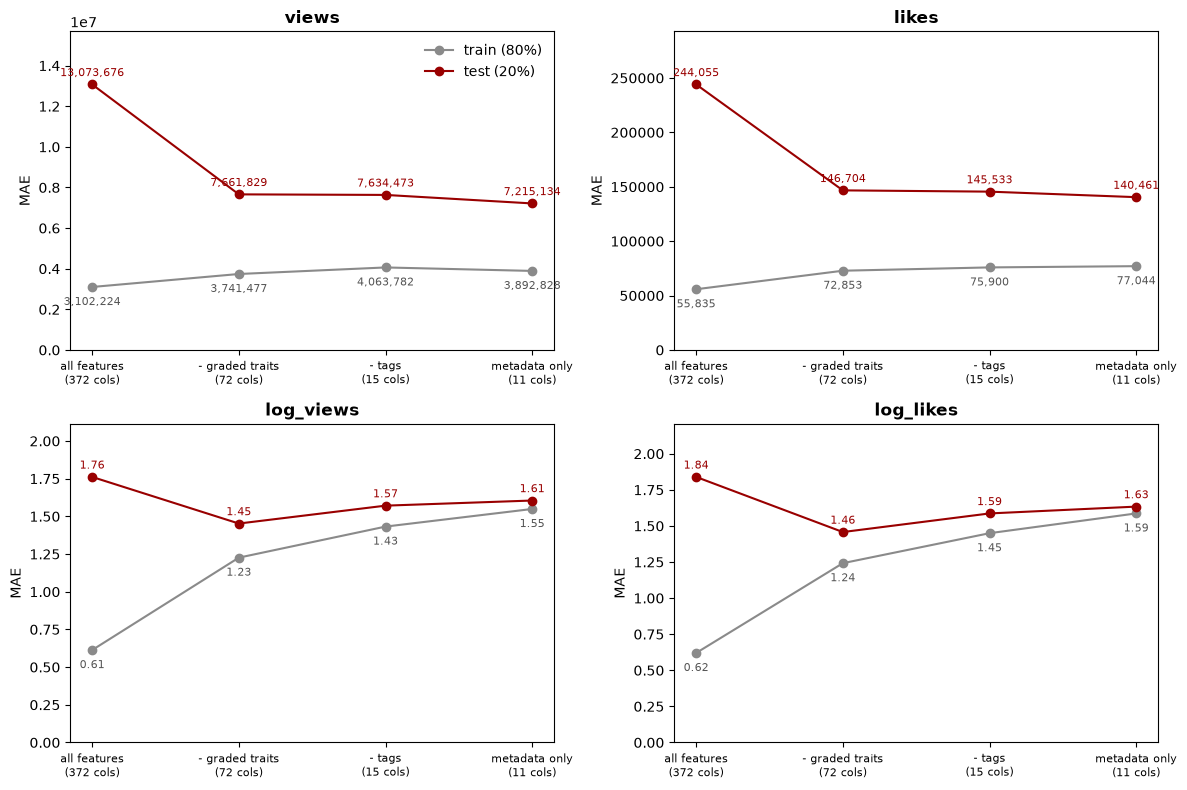

In [8]:
"""Four separate OLS models, starting from every column and removing one feature group at a time; each is fit on the
80% and scored on the 20% hold-out. Overfitting shows as the gap between train and test MAE: with every column in,
train error is lowest but test error is highest.
MAE is in views/likes for the raw targets and in log units for the log targets (0.5 = off by about 1.6x)."""
df_r2 = df_results.pivot(index="target", columns="split", values="R2").loc[list(targets)]
feature_steps = [
    ("all features", list(df_train.columns)),
    ("- graded traits", metadata_cols + binary_cols + tag_cols),
    ("- tags", metadata_cols + binary_cols),
    ("metadata only", metadata_cols),
]
df_step_rows = []
for target_name, target in targets.items():
    y_train = target.loc[df_train.index]
    y_test = target.loc[df_test.index]
    for step_name, step_cols in feature_steps:
        coef = fit_ols(df_train[step_cols], y_train)
        pred_train = predict_ols(coef, df_train[step_cols])
        pred_test = predict_ols(coef, df_test[step_cols])
        df_step_rows.append({"target": target_name, "step": step_name, "n_columns": len(step_cols),
                             "train_MAE": mean_absolute_error(y_train, pred_train), "test_MAE": mean_absolute_error(y_test, pred_test),
                             "train_R2": r2_score(y_train, pred_train), "test_R2": r2_score(y_test, pred_test)})
df_steps = pd.DataFrame(df_step_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, target_name in zip(axes.ravel(), ["views", "likes", "log_views", "log_likes"]):
    df_target = df_steps[df_steps["target"] == target_name]
    positions = np.arange(len(df_target))
    ax.plot(positions, df_target["train_MAE"], color="#8A8A8A", marker="o", label="train (80%)")
    ax.plot(positions, df_target["test_MAE"], color="#990000", marker="o", label="test (20%)")
    for position, train_mae, test_mae in zip(positions, df_target["train_MAE"], df_target["test_MAE"]):
        ax.annotate(f"{train_mae:,.2f}" if "log" in target_name else f"{train_mae:,.0f}", (position, train_mae), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8, color="#555555")
        ax.annotate(f"{test_mae:,.2f}" if "log" in target_name else f"{test_mae:,.0f}", (position, test_mae), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, color="#990000")
    ax.set_xticks(positions)
    ax.set_xticklabels([f"{step}\n({n} cols)" for step, n in zip(df_target["step"], df_target["n_columns"])], fontsize=8)
    ax.set_ylim(0, df_target[["train_MAE", "test_MAE"]].to_numpy().max() * 1.2)
    ax.set_ylabel("MAE")
    ax.set_title(target_name, fontweight="bold")
axes[0, 0].legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## Predicted vs actual (test set)

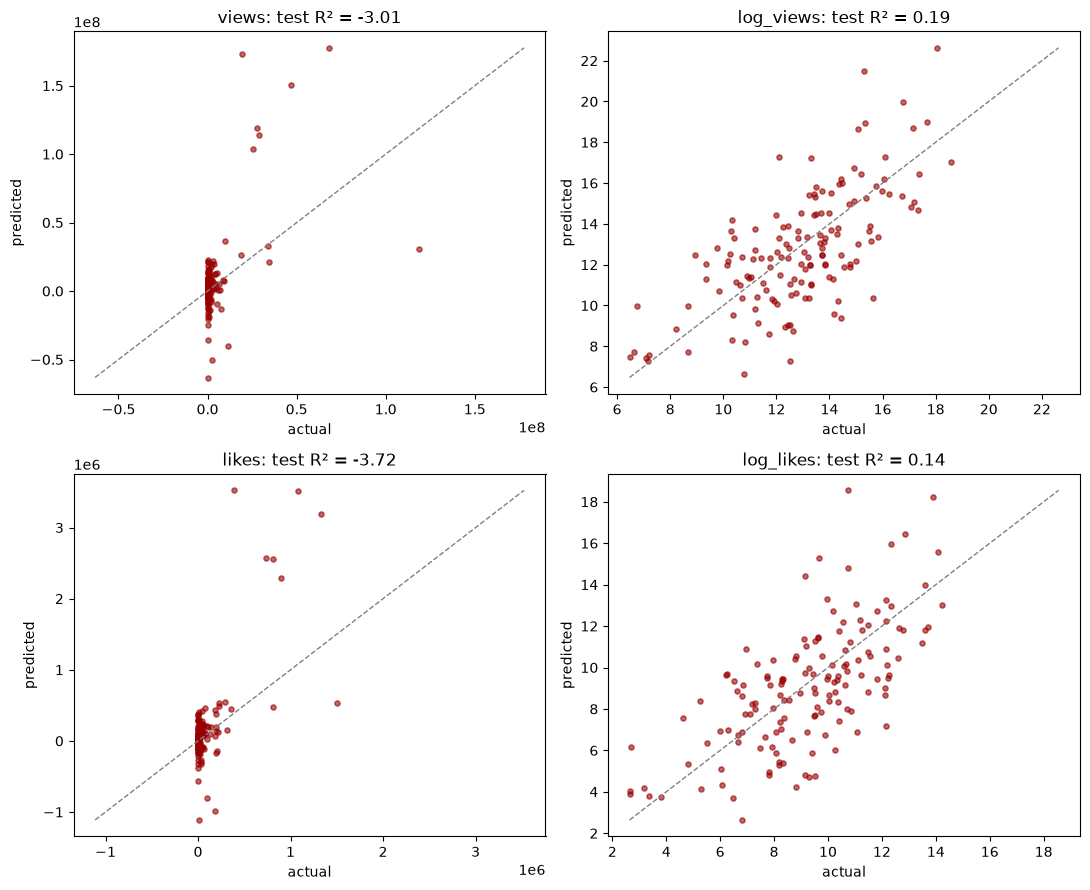

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (target_name, target) in zip(axes.ravel(), targets.items()):
    actual = target.loc[df_test.index]
    ax.scatter(actual, test_predictions[target_name], s=14, alpha=0.6, color="#990000")
    low, high = min(actual.min(), test_predictions[target_name].min()), max(actual.max(), test_predictions[target_name].max())
    ax.plot([low, high], [low, high], color="gray", linestyle="--", linewidth=1)
    test_r2 = df_r2.loc[target_name, "test"]
    ax.set_title(f"{target_name}: test R² = {test_r2:.2f}")
    ax.set_xlabel("actual")
    ax.set_ylabel("predicted")
plt.tight_layout()
plt.show()

## Save the design matrix for the next notebooks

In [10]:
"""Same rows, columns and train/test split for 02_lasso, so the comparison is like for like."""
df_matrix = df_encoded.assign(id=df_model["id"], channel_id=df_model["channel_id"], views=df_model["views"], likes=df_model["likes"],
                              split=np.where(df_encoded.index.isin(df_test.index), "test", "train"))
os.makedirs(os.path.dirname(config.MODEL_MATRIX_PATH), exist_ok=True)
df_matrix.to_csv(config.MODEL_MATRIX_PATH, index=False)
df_results.to_csv(os.path.join(os.path.dirname(config.MODEL_MATRIX_PATH), "ols_results.csv"), index=False)
df_steps.to_csv(os.path.join(os.path.dirname(config.MODEL_MATRIX_PATH), "ols_feature_steps.csv"), index=False)
print(f"wrote {config.MODEL_MATRIX_PATH}: {df_matrix.shape}")

wrote /Users/leoyang/Downloads/Github Repos/DSO_585_project/data/processed/model_matrix.csv: (726, 377)
